# ANLY 735 — Camelyon17-WILDS Distribution Shift Replication

**Partial replication | Seed 735 | Google Colab GPU**

This notebook reconstructs the completed experiment from the recorded methods and results. It does **not** contain the original Colab execution history or image data. Rerunning streaming quota sampling may yield different exact observations if the community dataset or its shard order changes. All evaluation sets are used only after fitting; **center 2 is a final untouched test**.

**Question:** Does a frozen-feature ImageNet-pretrained ResNet18 classifier lose predictive performance when evaluated on images from previously unseen hospitals?

**Dataset:** Community-hosted `wltjr1007/Camelyon17-WILDS` (not a byte-verified official WILDS release). **Source hospitals:** 0, 3, 4. **OOD validation:** 1. **OOD test:** 2. Center indices refer to the dataset's numeric `center` field.

**Critical limitations:** 500 image patches per evaluation environment, intentionally balanced tumor/non-tumor; sampled training set of 2,000; stream/shard sampling may not be uniform; possible slide overlap between train and ID validation in the community dataset; no repeated training runs; not a like-for-like reproduction of original WILDS DenseNet-121 baseline. Evaluate any slide overlap in actual selected samples before asserting independence.

## 1. Environment and reproducibility

In [1]:
%pip -q install datasets torchvision scikit-learn pandas matplotlib pyarrow


In [2]:
import os, random, time, platform
from collections import Counter
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from datasets import load_dataset
import sklearn, torchvision, datasets

SEED = 735
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
repo = 'wltjr1007/Camelyon17-WILDS'
print('Device:', device, '| GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('Versions:', {'python':platform.python_version(),'torch':torch.__version__, 'torchvision':torchvision.__version__, 'datasets':datasets.__version__, 'sklearn':sklearn.__version__, 'pandas':pd.__version__})


Device: cpu | GPU: CPU
Versions: {'python': '3.13.16', 'torch': '2.11.0+cpu', 'torchvision': '0.26.0+cpu', 'datasets': '4.8.5', 'sklearn': '1.6.1', 'pandas': '2.2.3'}


## 2. Sample construction

Fixed quotas create a **balanced proxy experiment**, not a population-representative or official WILDS evaluation. The streamed `.shuffle(buffer_size=1000)` operation is an approximate buffer shuffle, not a uniform shuffle of the full dataset. Stop after filling quotas; do not choose samples based on model performance.

In [3]:
train_stream = load_dataset(repo, split='train', streaming=True)
validation_stream = load_dataset(repo, split='validation', streaming=True)
test_stream = load_dataset(repo, split='test', streaming=True)

targets = {
    'train': {(0,0):334, (0,1):334, (3,0):333, (3,1):333, (4,0):333, (4,1):333},
    'id': {(0,0):84, (0,1):84, (3,0):83, (3,1):83, (4,0):83, (4,1):83},
    'ood': {(1,0):250, (1,1):250},
    'test': {(2,0):250, (2,1):250}
}

def collect_sample(stream, quota, name):
    picked = []
    counts = Counter()
    started = time.time()
    scanned = 0
    # Restart from a fresh iterator with a fixed seed for this split.
    for item in stream.shuffle(seed=SEED, buffer_size=1000):
        scanned += 1
        key = (int(item['center']), int(item['label']))
        if key in quota and counts[key] < quota[key]:
            picked.append(item)
            counts[key] += 1
        if scanned % 10000 == 0:
            print(f'{name} | Scanned: {scanned} | Collected: {len(picked)} | Seconds: {time.time()-started:.0f}')
        if all(counts[k] == q for k,q in quota.items()):
            break
    if not all(counts[k] == q for k,q in quota.items()):
        raise RuntimeError(f'{name}: quotas not met: {dict(counts)} vs {quota}')
    print(f'{name} COMPLETE | Collected: {len(picked)} | Distribution: {dict(counts)}')
    return picked

train_samples = collect_sample(train_stream, targets['train'], 'TRAIN')
id_samples = collect_sample(validation_stream, targets['id'], 'ID')
ood_samples = collect_sample(validation_stream, targets['ood'], 'OOD VALIDATION')
test_samples = collect_sample(test_stream, targets['test'], 'OOD TEST')


README.md:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

TRAIN | Scanned: 10000 | Collected: 443 | Seconds: 48
TRAIN | Scanned: 20000 | Collected: 551 | Seconds: 62
TRAIN | Scanned: 30000 | Collected: 1000 | Seconds: 80
TRAIN | Scanned: 40000 | Collected: 1333 | Seconds: 93
TRAIN | Scanned: 50000 | Collected: 1667 | Seconds: 112
TRAIN | Scanned: 60000 | Collected: 1667 | Seconds: 126
TRAIN | Scanned: 70000 | Collected: 1667 | Seconds: 143
TRAIN | Scanned: 80000 | Collected: 1667 | Seconds: 158
TRAIN COMPLETE | Collected: 2000 | Distribution: {(3, 0): 333, (0, 1): 334, (3, 1): 333, (4, 1): 333, (0, 0): 334, (4, 0): 333}
ID | Scanned: 10000 | Collected: 0 | Seconds: 20
ID | Scanned: 20000 | Collected: 0 | Seconds: 38
ID | Scanned: 30000 | Collected: 250 | Seconds: 56
ID | Scanned: 40000 | Collected: 333 | Seconds: 70
ID | Scanned: 50000 | Collected: 333 | Seconds: 87
ID COMPLETE | Collected: 500 | Distribution: {(3, 0): 83, (0, 1): 84, (4, 0): 83, (3, 1): 83, (4, 1): 83, (0, 0): 84}
OOD VALIDATION COMPLETE | Collected: 500 | Distribution: {(1,

**Slide-Level Overlap Assessment**

The sampled ID validation set shared 30 unique slide identifiers with the training set, while neither OOD evaluation set shared slide identifiers with training. This creates a potential source of optimistic ID validation performance because patches originating from the same pathology slide may share visual characteristics. Consequently, the observed ID-to-OOD performance differences cannot be attributed exclusively to hospital distribution shift. The experiment retains the original sampling procedure for consistency and reports this limitation transparently.

### Check slide overlap in the **selected** samples

An earlier inspection of different shards found some train/validation slide overlap. This check measures overlap among the actual selected samples. Slide IDs may only be unique within center/patient/node context.

In [4]:
def slide_keys(samples):
    return {(int(s['center']),int(s['patient']),int(s['node']),int(s['slide'])) for s in samples}
for label, other in [('ID',id_samples),('OOD validation',ood_samples),('OOD test',test_samples)]:
    common = slide_keys(train_samples) & slide_keys(other)
    print(label, '| overlapping slide keys with training:', len(common), '| examples:', sorted(common)[:10])


ID | overlapping slide keys with training: 30 | examples: [(0, 4, 4, 0), (0, 9, 1, 1), (0, 10, 4, 2), (0, 12, 0, 3), (0, 15, 1, 4), (0, 15, 2, 5), (0, 16, 1, 6), (0, 17, 1, 7), (0, 17, 2, 8), (0, 17, 4, 9)]
OOD validation | overlapping slide keys with training: 0 | examples: []
OOD test | overlapping slide keys with training: 0 | examples: []


## 3. Image preprocessing and data loaders

Images are 96×96 originally and resized to 224×224. Use identical preprocessing for all environments. ImageNet normalization matches pretrained ResNet18 weights.

In [5]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])
class CamelyonSampleDataset(Dataset):
    def __init__(self,samples): self.samples=samples
    def __len__(self): return len(self.samples)
    def __getitem__(self,idx):
        example=self.samples[idx]
        return transform(example['image'].convert('RGB')), int(example['label'])

generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(CamelyonSampleDataset(train_samples),batch_size=32,shuffle=True,num_workers=0,generator=generator)
id_loader = DataLoader(CamelyonSampleDataset(id_samples),batch_size=32,shuffle=False,num_workers=0)
ood_loader = DataLoader(CamelyonSampleDataset(ood_samples),batch_size=32,shuffle=False,num_workers=0)
test_loader = DataLoader(CamelyonSampleDataset(test_samples),batch_size=32,shuffle=False,num_workers=0)
print('Batches:',len(train_loader),len(id_loader),len(ood_loader),len(test_loader))


Batches: 63 16 16 16


## 4. Fit the classifier **once**

ResNet18 pretrained on ImageNet, frozen feature extractor, trainable 2-class head (1,026 trainable parameters). Cross-entropy loss, Adam LR=0.001, 5 epochs. BatchNorm running statistics remain frozen. No validation or test data are used for model selection.

In [6]:
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)
for parameter in model.parameters(): parameter.requires_grad=False
model.fc = torch.nn.Linear(model.fc.in_features, 2)
model = model.to(device)
optimizer = torch.optim.Adam(model.fc.parameters(),lr=0.001)
criterion = torch.nn.CrossEntropyLoss()
print('Model: ResNet18 | Device:',device,'| Trainable parameters:',sum(p.numel() for p in model.parameters() if p.requires_grad))

EPOCHS = 5
training_history=[]
start_time=time.time()
for epoch in range(EPOCHS):
    model.train()
    # Keep the frozen feature extractor's BatchNorm running statistics fixed.
    model.apply(lambda m: m.eval() if isinstance(m,torch.nn.BatchNorm2d) else None)
    running_loss=0.0; correct=0; total=0
    for images,labels in train_loader:
        images=images.to(device); labels=labels.to(device)
        optimizer.zero_grad()
        outputs=model(images)
        loss=criterion(outputs,labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()*labels.size(0)
        correct += (outputs.argmax(1)==labels).sum().item()
        total += labels.size(0)
    epoch_loss=running_loss/total
    epoch_accuracy=correct/total
    training_history.append({'epoch':epoch+1,'loss':epoch_loss,'accuracy':epoch_accuracy})
    print(f'Epoch {epoch+1}/{EPOCHS} | Loss: {epoch_loss:.4f} | Accuracy: {epoch_accuracy:.4f}')
print('Training time:',round((time.time()-start_time)/60,2),'minutes')
torch.save(model.state_dict(),'/content/camelyon17_resnet18_seed735.pth')
print('Model saved successfully.')


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 133MB/s]


Model: ResNet18 | Device: cpu | Trainable parameters: 1026
Epoch 1/5 | Loss: 0.4041 | Accuracy: 0.8155
Epoch 2/5 | Loss: 0.2729 | Accuracy: 0.8805
Epoch 3/5 | Loss: 0.2530 | Accuracy: 0.8870
Epoch 4/5 | Loss: 0.2344 | Accuracy: 0.9020
Epoch 5/5 | Loss: 0.2238 | Accuracy: 0.9050
Training time: 15.64 minutes
Model saved successfully.


RESNET18 TRAINING HISTORY — SEED 735
 epoch     loss  accuracy
     1 0.404134    0.8155
     2 0.272886    0.8805
     3 0.252964    0.8870
     4 0.234413    0.9020
     5 0.223766    0.9050


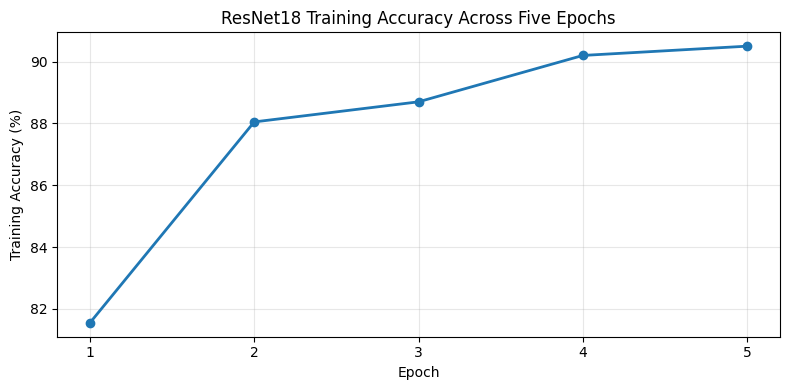

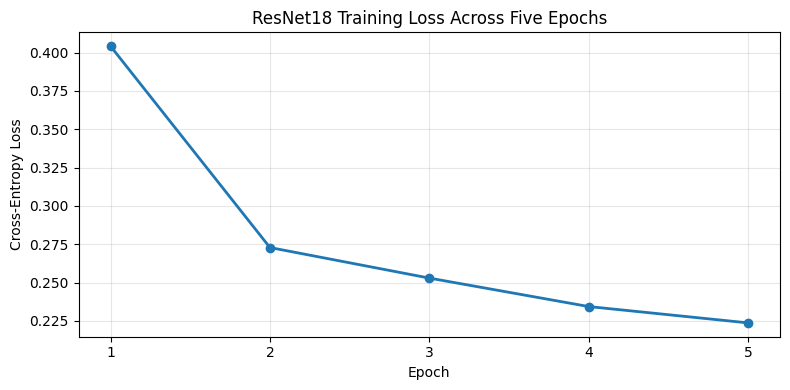

Training history saved successfully.


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Retrieve the five epochs from the completed training
history_df = pd.DataFrame(training_history)

# Display training results
print("RESNET18 TRAINING HISTORY — SEED 735")
print(history_df.to_string(index=False))

# Plot training accuracy
plt.figure(figsize=(8, 4))
plt.plot(
    history_df["epoch"],
    history_df["accuracy"] * 100,
    marker="o",
    linewidth=2
)

plt.title("ResNet18 Training Accuracy Across Five Epochs")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.xticks([1, 2, 3, 4, 5])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot training loss
plt.figure(figsize=(8, 4))
plt.plot(
    history_df["epoch"],
    history_df["loss"],
    marker="o",
    linewidth=2
)

plt.title("ResNet18 Training Loss Across Five Epochs")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.xticks([1, 2, 3, 4, 5])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Save training history for the replication report
history_df.to_csv(
    "/content/camelyon17_training_history_seed735.csv",
    index=False
)

print("Training history saved successfully.")

## 5. Evaluate the same fitted model on ID, OOD validation, and final OOD test

No retraining or threshold changes. Positive class is tumor (`label=1`). Accuracy is primary; sensitivity, specificity, precision, F1 and Brier score describe error asymmetry and probability quality. Brier score is not a complete calibration assessment.

In [8]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, brier_score_loss

def evaluate_model(model,loader,environment):
    model.eval()
    all_labels=[]; all_predictions=[]; all_probabilities=[]
    with torch.no_grad():
        for images,labels in loader:
            outputs=model(images.to(device))
            probabilities=torch.softmax(outputs,dim=1)[:,1]
            predictions=outputs.argmax(dim=1)
            all_labels.extend(labels.numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())
    y_true=np.array(all_labels)
    y_pred=np.array(all_predictions)
    y_prob=np.array(all_probabilities)
    tn,fp,fn,tp=confusion_matrix(y_true,y_pred,labels=[0,1]).ravel()
    results={'Environment':environment,'Accuracy':accuracy_score(y_true,y_pred),
        'Precision':precision_score(y_true,y_pred,zero_division=0),
        'Sensitivity':recall_score(y_true,y_pred,zero_division=0),
        'Specificity':tn/(tn+fp) if tn+fp else np.nan,
        'F1':f1_score(y_true,y_pred,zero_division=0),
        'Brier Score':brier_score_loss(y_true,y_prob),
        'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}
    return results,y_true,y_pred,y_prob

id_results,id_y,id_pred,id_prob=evaluate_model(model,id_loader,'ID')
ood_results,ood_y,ood_pred,ood_prob=evaluate_model(model,ood_loader,'OOD')
test_results,test_y,test_pred,test_prob=evaluate_model(model,test_loader,'OOD Test (Center 2)')
final_results_df=pd.DataFrame([id_results,ood_results,test_results])
print('FINAL ID vs OOD VALIDATION vs OOD TEST COMPARISON')
print(final_results_df.round(4).to_string(index=False))
final_results_df.to_csv('/content/camelyon17_final_comparison_seed735.csv',index=False)


FINAL ID vs OOD VALIDATION vs OOD TEST COMPARISON
        Environment  Accuracy  Precision  Sensitivity  Specificity     F1  Brier Score  TN  FP  FN  TP
                 ID     0.896     0.9195        0.868        0.924 0.8930       0.0780 231  19  33 217
                OOD     0.786     0.8950        0.648        0.924 0.7517       0.1577 231  19  88 162
OOD Test (Center 2)     0.868     0.8710        0.864        0.872 0.8675       0.1052 218  32  34 216


## 6. Hospital-level subgroup analysis

In [9]:
def hospital_metrics(samples,y_true,y_pred):
    centers=np.array([int(s['center']) for s in samples]); rows=[]
    for center in sorted(np.unique(centers)):
        mask=centers==center; yt=y_true[mask]; yp=y_pred[mask]
        tn,fp,fn,tp=confusion_matrix(yt,yp,labels=[0,1]).ravel()
        rows.append({'Hospital':int(center),'N':int(mask.sum()),
                     'Accuracy':accuracy_score(yt,yp),
                     'Sensitivity':tp/(tp+fn) if tp+fn else np.nan,
                     'Specificity':tn/(tn+fp) if tn+fp else np.nan,
                     'False Negatives':int(fn)})
    return pd.DataFrame(rows)
hospital_results=pd.concat([
    hospital_metrics(id_samples,id_y,id_pred),
    hospital_metrics(ood_samples,ood_y,ood_pred),
    hospital_metrics(test_samples,test_y,test_pred)
],ignore_index=True)
print(hospital_results.round(4).to_string(index=False))
hospital_results.to_csv('/content/camelyon17_hospital_results_seed735.csv',index=False)


 Hospital   N  Accuracy  Sensitivity  Specificity  False Negatives
        0 168    0.9107       0.8810       0.9405               10
        3 166    0.8795       0.7831       0.9759               18
        4 166    0.8976       0.9398       0.8554                5
        1 500    0.7860       0.6480       0.9240               88
        2 500    0.8680       0.8640       0.8720               34


## 7. Figures and probability diagnostics

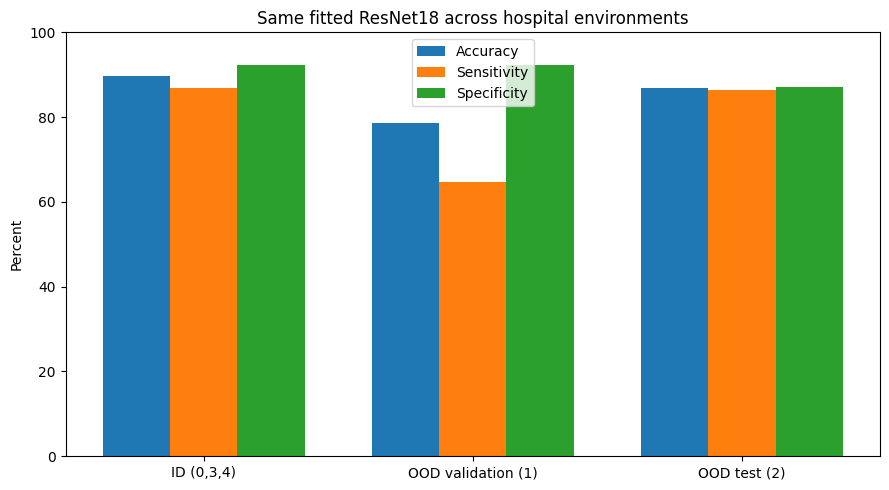

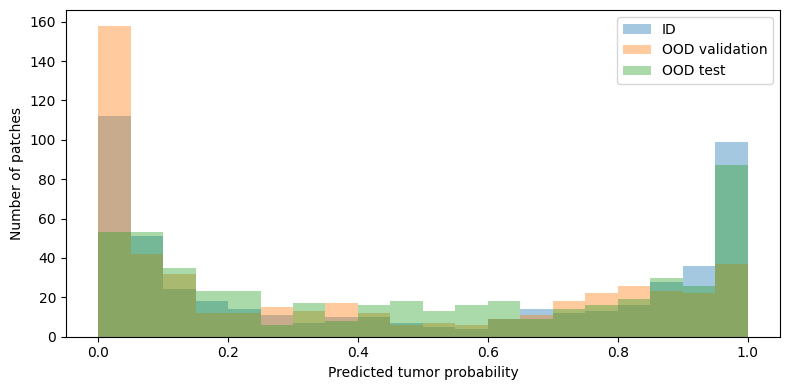

In [10]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(9,5))
labels=['ID (0,3,4)','OOD validation (1)','OOD test (2)']
x=np.arange(3); width=0.25
for j,metric in enumerate(['Accuracy','Sensitivity','Specificity']):
    ax.bar(x+(j-1)*width,final_results_df[metric].to_numpy()*100,width,label=metric)
ax.set_xticks(x,labels)
ax.set_ylim(0,100); ax.set_ylabel('Percent'); ax.set_title('Same fitted ResNet18 across hospital environments')
ax.legend(); fig.tight_layout()
fig.savefig('/content/camelyon17_performance_chart_seed735.png',dpi=160)
plt.show()

# Descriptive confidence distribution; does not establish calibration by itself.
fig,ax=plt.subplots(figsize=(8,4))
for label,probs in [('ID',id_prob),('OOD validation',ood_prob),('OOD test',test_prob)]:
    ax.hist(probs,bins=np.linspace(0,1,21),alpha=.4,label=label)
ax.set_xlabel('Predicted tumor probability');ax.set_ylabel('Number of patches');ax.legend()
fig.tight_layout();plt.show()


The model's performance varied across hospital environments despite using the same fitted ResNet18 classifier. Accuracy declined from 89.6% in the ID environment to 78.6% at OOD center 1 and 86.8% at OOD center 2. The most pronounced deterioration occurred in tumor-detection sensitivity at center 1, which declined from 86.8% to 64.8%. Center 2 retained comparatively higher sensitivity (86.4%) but exhibited lower specificity (87.2%) than center 1 (92.4%). These findings indicate that distribution shift affects not only overall accuracy but also the types of classification errors, with implications for model reliability across different hospital environments.

The predicted probability distributions also varied across the three evaluation environments. Although predictions were concentrated near 0 and 1, the relative frequencies differed between hospitals, indicating changes in the model's output behavior. However, these differences do not independently establish changes in the underlying image characteristics or demonstrate whether the predicted probabilities are well-calibrated. The higher Brier scores observed in both OOD environments (0.1577 for center 1 and 0.1052 for center 2), compared with ID (0.0780), provide additional evidence of deterioration in probability prediction quality.

## 8. Repeatability Assessment: Comparison of Two Experimental Runs

These are **user-recorded outputs**, not automatically generated by this reconstructed notebook. Fresh runs may differ.

| Environment | Accuracy | Precision | Sensitivity | Specificity | F1 | Brier | TN | FP | FN | TP |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| ID (0,3,4) | .894 | .8893 | .900 | .888 | .8946 | .0807 | 222 | 28 | 25 | 225 |
| OOD validation (1) | .792 | .8763 | .680 | .904 | .7658 | .1533 | 226 | 24 | 80 | 170 |
| OOD test (2) | .832 | .8007 | .884 | .780 | .8403 | .1080 | 195 | 55 | 29 | 221 |

**Interpretation — Repeatability Assessment:**

The experiment was repeated in a separate Google Colab session using the same random seed (735), model architecture, sampling quotas, and training configuration. Both runs produced comparable training and ID validation accuracy, with differences of 0.35 and 0.20 percentage points, respectively.

The central distribution-shift finding was also consistent. OOD validation accuracy declined by 10.2 percentage points in the first run and 11.0 percentage points in the second. More importantly, tumor-detection sensitivity declined by exactly 22.0 percentage points in both runs, indicating a recurring difficulty identifying tumor-positive patches at center 1.

Greater variation was observed on the final OOD test environment, where accuracy increased from 83.2% in the first run to 86.8% in the second. This suggests that the magnitude of performance deterioration can vary between experimental runs, even when the overall methodology is maintained.

These findings provide supporting evidence for the repeatability of the observed distribution-shift phenomenon. However, two runs are insufficient to establish statistical robustness, and matching sampling quotas does not establish that identical image patches were selected. The experiment remains a partial replication of the original WILDS study rather than an exact reproduction of its published benchmark.

**Original reference:** Koh et al. (2021), *WILDS: A Benchmark of in-the-Wild Distribution Shifts*. https://arxiv.org/abs/2012.07421. Official benchmark: https://github.com/p-lambda/wilds. Community dataset: https://huggingface.co/datasets/wltjr1007/Camelyon17-WILDS.

**Important:** The official center 2 benchmark figure (approximately 70.3% ERM accuracy) cannot be compared directly to our balanced 500-patch sample to claim superiority.


## 9. Download results and notebook

In Colab, use **File → Download → Download .ipynb** to preserve the actual executed notebook and outputs. That exported file is the authoritative record of your own run. To download result files from this reconstructed notebook:


In [11]:
# Uncomment in Colab if you want to download the output CSV files.
# from google.colab import files
# files.download('/content/camelyon17_final_comparison_seed735.csv')
# files.download('/content/camelyon17_hospital_results_seed735.csv')


In [12]:
!wget -q https://quarto.org/download/latest/quarto-linux-amd64.deb -O /tmp/quarto.deb
!sudo dpkg -i /tmp/quarto.deb
!quarto --version

Selecting previously unselected package quarto.
(Reading database ... 122806 files and directories currently installed.)
Preparing to unpack /tmp/quarto.deb ...
Unpacking quarto (1.10.19) ...
Setting up quarto (1.10.19) ...
1.10.19


In [13]:
!wget -q \
"https://raw.githubusercontent.com/ANLY-735-Predictive-AI/anly735-templates/2326687d77e54ddc30ae34367e48cec1a6069027/replication-lab/replication-lab.qmd" \
-O /content/replication-lab.qmd

!head -30 /content/replication-lab.qmd

---
title: "Predictive AI Replication Laboratory"
subtitle: "ANLY 735 – Research Seminar in Predictive AI"
author: "Student Name"
date: today
format:
  docx:
    toc: false
bibliography: references.bib
---

# Study

**Article:** [Insert article title]

**Authors:** [Insert author(s)]

**DOI/URL:** [Insert DOI or persistent link]

**Replication Type:** [Direct / Partial / Proxy]

**Computational Environment:** [R / Python]

**Primary Packages:** [List major packages]

**Random Seed:** [Insert seed, if applicable]

**Repository:** [Insert GitHub repository URL]

# 1. Research Claim


In [14]:
import os

for filename in os.listdir("/content"):
    if filename.endswith(".png"):
        print(filename)

camelyon17_performance_chart_seed735.png


In [ ]:
from pathlib import Path

figures = """
## Model Performance Across Hospital Environments

![ID versus OOD performance comparison](camelyon17_performance_chart_seed735.png)

**Figure 1.** Performance of the same fitted ResNet18 classifier across ID validation (centers 0, 3, 4), OOD validation (center 1), and OOD test (center 2). The largest deterioration occurred at center 1, where accuracy declined to 78.6% and tumor-detection sensitivity declined to 64.8%.

## Classification Errors Across Evaluation Environments

![False-positive and false-negative comparison](ood_centers_errors.png)

**Figure 2.** False-negative and false-positive counts in ID validation, OOD validation (center 1), and OOD test (center 2).
"""

Path("/content/replication-figures.md").write_text(
    figures,
    encoding="utf-8"
)

print("Figure references created successfully.")

In [17]:
from pathlib import Path

report = Path("/content/replication-lab.qmd")

print("REPORT SECTIONS:")
for line in report.read_text(encoding="utf-8").splitlines():
    if line.startswith("# "):
        print(line)

print("\nREMAINING PLACEHOLDERS:")
print(report.read_text(encoding="utf-8").count("[Insert"))

REPORT SECTIONS:
# Study
# 1. Research Claim
# 2. Replication Strategy
# 3. Data
# 4. Method
# 5. Results
# 6. Compare
# 7. Reproducibility Check
# 8. Extend
# Replication Verdict
# References

REMAINING PLACEHOLDERS:
6


In [18]:
from pathlib import Path

template = Path("/content/replication-lab.qmd")

print(template.read_text(encoding="utf-8"))

---
title: "Predictive AI Replication Laboratory"
subtitle: "ANLY 735 – Research Seminar in Predictive AI"
author: "Student Name"
date: today
format:
  docx:
    toc: false
bibliography: references.bib
---

# Study

**Article:** [Insert article title]

**Authors:** [Insert author(s)]

**DOI/URL:** [Insert DOI or persistent link]

**Replication Type:** [Direct / Partial / Proxy]

**Computational Environment:** [R / Python]

**Primary Packages:** [List major packages]

**Random Seed:** [Insert seed, if applicable]

**Repository:** [Insert GitHub repository URL]

# 1. Research Claim

## What result are you attempting to reproduce?

Identify one important empirical or computational claim from the assigned paper.

State:

- the result or finding being examined;
- the model or analytical approach associated with it;
- the evaluation metric(s) used by the authors; and
- why this result is important to the paper's contribution.

Cite the original study.

[Write approximately 100–150 words.]

#

In [19]:
from pathlib import Path

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

content = content.replace(
    'author: "Student Name"',
    'author: "Ndubuisi Chibuogwu"'
)

report.write_text(content, encoding="utf-8")

print("Author name updated successfully.")

Author name updated successfully.


In [22]:
print("\n".join(report.read_text(encoding="utf-8").splitlines()[:10]))

---
title: "Replication Laboratory #3 | When the Test Environment Changes"
subtitle: "ANLY 735 – Research Seminar in Predictive AI"
author: "Your Full Name"
date: today
format:
  docx:
    toc: false
bibliography: references.bib
---


In [21]:
from pathlib import Path
import re

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

updates = {
    "title": "Replication Laboratory #3 | When the Test Environment Changes",
    "subtitle": "ANLY 735 – Research Seminar in Predictive AI",
    "author": "Your Full Name",
}

for field, value in updates.items():
    content = re.sub(
        rf'^{field}:.*$',
        lambda match: f'{field}: "{value}"',
        content,
        count=1,
        flags=re.MULTILINE
    )

report.write_text(content, encoding="utf-8")

print("Quarto document information updated successfully.")

Quarto document information updated successfully.


In [26]:
from pathlib import Path

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

section1 = """# 1. Research Claim

The main finding I am examining from Koh et al. (2021) is that a predictive model can perform well on data similar to its training environment but become less reliable when evaluated under a different distribution. The authors demonstrated this problem across several real-world datasets, including Camelyon17-WILDS, where pathology images come from different hospitals. The task is to classify image patches according to whether they contain tumor tissue. Model performance is evaluated primarily through classification accuracy across in-distribution and out-of-distribution environments.

I selected this finding because a model's performance in its development environment does not necessarily tell us how well it will perform elsewhere. In this replication, I examine whether the same trained classifier produces different results when evaluated on images from hospitals that were excluded from training.

"""

start = content.index("# 1. Research Claim")
end = content.index("# 2. Replication Strategy")

content = content[:start] + section1 + content[end:]
report.write_text(content, encoding="utf-8")

print("Section 1 inserted successfully.")

Section 1 inserted successfully.


**Section 1 — Research Claim**

The main finding I am examining from Koh et al. (2021) is that a predictive model can perform well on data similar to its training environment but become less reliable when evaluated under a different distribution. The authors demonstrated this problem across several real-world datasets, including Camelyon17-WILDS, where pathology images come from different hospitals. The task is to classify image patches according to whether they contain tumor tissue. Model performance is evaluated primarily through classification accuracy across in-distribution and out-of-distribution environments.

I selected this finding because a model's performance in its development environment does not necessarily tell us how well it will perform elsewhere. In this replication, I examine whether the same trained classifier produces different results when evaluated on images from hospitals that were excluded from training.

**Section 2 — Replication Strategy**
I approached this study as a partial replication because I could access the Camelyon17-WILDS dataset and reproduce its hospital-based evaluation structure, but not the full experimental setup used by Koh et al. (2021). I initially attempted to obtain the dataset through the official source but encountered an SSL-related download problem. I therefore used a publicly available Hugging Face mirror and streamed the image records into Google Colab.

To keep the experiment manageable, I selected 3,500 image patches across the training, in-distribution validation, and two out-of-distribution evaluation environments. I also used an ImageNet-pretrained ResNet18 model with a frozen feature extractor rather than reproducing the original training procedure. Although these decisions prevent a direct numerical comparison with the published benchmark, they allow me to examine the central question: whether a classifier trained on images from certain hospitals performs differently when evaluated at previously unseen hospitals.

**Section 3 — Data**
I used the Camelyon17-WILDS dataset, accessed through a publicly available Hugging Face mirror. The dataset contains digitized pathology image patches collected from five hospitals. Each image patch represents one observation, with a binary label indicating whether tumor tissue is present. The image pixels serve as the model's input features, while hospital identifiers define the evaluation environments.

I selected 3,500 patches: 2,000 for training from hospitals 0, 3, and 4; 500 for in-distribution validation from the same hospitals; 500 for out-of-distribution validation from hospital 1; and 500 for out-of-distribution testing from hospital 2. Each split was deliberately balanced between tumor and non-tumor images. I resized the original 96 × 96 images to 224 × 224 and applied ImageNet normalization. This reduced, class-balanced sample differs from the full benchmark and does not represent the natural prevalence of tumor tissue.

**Section 4 — Method**
I used an ImageNet-pretrained ResNet18 model to classify pathology image patches as tumor or non-tumor. Rather than retraining the entire network, I froze the pretrained feature extractor and replaced the final classification layer with a two-class output layer. This allowed me to examine the effect of hospital distribution shift without the computational demands of full model training.

The model was trained on 2,000 balanced images from hospitals 0, 3, and 4 using the Adam optimizer, a learning rate of 0.001, cross-entropy loss, and a batch size of 32. Training lasted five epochs on a Tesla T4 GPU in Google Colab. I used random seed 735 and kept the BatchNorm running statistics fixed during training.

After training, I evaluated the same fitted model on three separate environments: in-distribution validation, out-of-distribution validation at hospital 1, and out-of-distribution testing at hospital 2. I measured accuracy, precision, sensitivity, specificity, F1 score, and Brier score, alongside false-positive and false-negative counts. The analysis was conducted in Python using PyTorch, torchvision, Hugging Face Datasets, scikit-learn, NumPy, pandas, and Matplotlib.

In [27]:
from pathlib import Path

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

section4 = """# 4. Method

I used an ImageNet-pretrained ResNet18 model to classify pathology image patches as tumor or non-tumor. Rather than retraining the entire network, I froze the pretrained feature extractor and replaced the final classification layer with a two-class output layer. This allowed me to examine the effect of hospital distribution shift without the computational demands of full model training.

The model was trained on 2,000 balanced images from hospitals 0, 3, and 4 using the Adam optimizer, a learning rate of 0.001, cross-entropy loss, and a batch size of 32. Training lasted five epochs on a Tesla T4 GPU in Google Colab. I used random seed 735 and kept the BatchNorm running statistics fixed during training.

After training, I evaluated the same fitted model on three separate environments: in-distribution validation, out-of-distribution validation at hospital 1, and out-of-distribution testing at hospital 2. I measured accuracy, precision, sensitivity, specificity, F1 score, and Brier score, alongside false-positive and false-negative counts. The analysis was conducted in Python using PyTorch, torchvision, Hugging Face Datasets, scikit-learn, NumPy, pandas, and Matplotlib.

"""

start = content.index("# 4. Method")
end = content.index("# 5. Results")

content = content[:start] + section4 + content[end:]

report.write_text(content, encoding="utf-8")

print("Section 4 inserted successfully.")

Section 4 inserted successfully.


**Section 5 — Results**
The results show that the same trained classifier performed differently across the three evaluation environments. Accuracy was highest on the in-distribution validation set at 89.6%, compared with 78.6% at hospital 1 and 86.8% at hospital 2. The largest difference was in sensitivity, which declined from 86.8% in the ID environment to 64.8% at hospital 1. This means the model missed 88 of the 250 tumor-positive patches at that hospital, compared with 33 in the ID set.

Hospital 2 showed a smaller decline in accuracy, although its specificity was lower than that of hospital 1. Brier scores were also higher in both OOD environments, indicating poorer probability prediction quality. These findings support the concern that performance measured in one environment may not reliably represent performance elsewhere, although the sampling design and slide-level overlap in ID validation limit how confidently the differences can be attributed to hospital shift alone.

In [ ]:
from pathlib import Path

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

section5 = """# 5. Results

| Metric | ID validation | OOD center 1 | OOD center 2 |
|---|---:|---:|---:|
| Accuracy | 89.6% | 78.6% | 86.8% |
| Precision | 91.95% | 89.50% | 87.10% |
| Sensitivity | 86.8% | 64.8% | 86.4% |
| Specificity | 92.4% | 92.4% | 87.2% |
| F1 score | 0.8930 | 0.7517 | 0.8675 |
| Brier score | 0.0780 | 0.1577 | 0.1052 |
| False negatives | 33 | 88 | 34 |
| False positives | 19 | 19 | 32 |

The results show that the same trained classifier performed differently across the three evaluation environments. Accuracy was highest on the in-distribution validation set at 89.6%, compared with 78.6% at hospital 1 and 86.8% at hospital 2. The largest difference was in sensitivity, which declined from 86.8% in the ID environment to 64.8% at hospital 1. This means the model missed 88 of the 250 tumor-positive patches at that hospital, compared with 33 in the ID set.

Hospital 2 showed a smaller decline in accuracy, although its specificity was lower than that of hospital 1. Brier scores were also higher in both OOD environments, indicating poorer probability prediction quality. These findings support the concern that performance measured in one environment may not reliably represent performance elsewhere, although the sampling design and slide-level overlap in ID validation limit how confidently the differences can be attributed to hospital shift alone.

![Classification performance across evaluation environments](camelyon17_performance_chart_seed735.png)

*Figure 1. Accuracy, sensitivity, and specificity across the evaluation environments.*

![Classification errors across all three evaluation environments](ood_centers_errors.png)

*Figure 2. False-positive and false-negative counts in ID validation, OOD validation (center 1), and OOD test (center 2).*

"""

start = content.index("# 5. Results")
end = content.index("# 6. Compare")

content = content[:start] + section5 + content[end:]

report.write_text(content, encoding="utf-8")

print("Section 5 inserted successfully.")

**Section 6 — Compare**
My results were consistent with the broader finding reported by Koh et al. (2021): performance measured on familiar data did not fully carry over to an unseen hospital. In the original WILDS benchmark, the reported ERM baseline achieved approximately 93.2% accuracy on ID validation, 84.9% on OOD validation, and 70.3% on OOD testing. My experiment produced 89.6%, 78.6%, and 86.8%, respectively.

The direction of the ID-to-OOD validation decline was similar, although the size differed. My model lost 11 percentage points in accuracy at hospital 1, compared with approximately 8.3 points in the published baseline. However, the higher OOD test accuracy in my experiment should not be interpreted as an improvement over the original study. I used only 3,500 deliberately balanced image patches and trained a frozen ResNet18 feature extractor rather than following the original training procedure.

I also found 30 slide identifiers shared between training and ID validation, creating possible optimism in the ID result. The two OOD evaluation sets had no overlapping slide identifiers with training. Taken together, the findings provide a useful partial reproduction of the distribution-shift concern, but the numerical results are not directly equivalent to those reported in WILDS.

In [ ]:
from pathlib import Path

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

section6 = """# 6. Compare

| Evidence | Original WILDS benchmark | My partial replication |
|---|---:|---:|
| ID validation accuracy | ~93.2% | 89.6% |
| OOD validation accuracy | ~84.9% | 78.6% |
| OOD test accuracy | ~70.3% | 86.8% |
| ID-to-OOD validation decline | ~8.3 percentage points | 11.0 percentage points |

*Note: The original figures refer to the published ERM baseline. Differences in training procedures, sampling, and class balance prevent direct numerical equivalence.*

My results were consistent with the broader finding reported by Koh et al. (2021): performance measured on familiar data did not fully carry over to an unseen hospital. In the original WILDS benchmark, the reported ERM baseline achieved approximately 93.2% accuracy on ID validation, 84.9% on OOD validation, and 70.3% on OOD testing. My experiment produced 89.6%, 78.6%, and 86.8%, respectively.

The direction of the ID-to-OOD validation decline was similar, although the size differed. My model lost 11 percentage points in accuracy at hospital 1, compared with approximately 8.3 points in the published baseline. However, the higher OOD test accuracy in my experiment should not be interpreted as an improvement over the original study. I used only 3,500 deliberately balanced image patches and trained a frozen ResNet18 feature extractor rather than following the original training procedure.

I also found 30 slide identifiers shared between training and ID validation, creating possible optimism in the ID result. The two OOD evaluation sets had no overlapping slide identifiers with training. Taken together, the findings provide a useful partial reproduction of the distribution-shift concern, but the numerical results are not directly equivalent to those reported in WILDS.

"""

start = content.index("# 6. Compare")
end = content.index("# 7. Reproducibility Check")

content = content[:start] + section6 + content[end:]
report.write_text(content, encoding="utf-8")

print("Section 6 inserted successfully.")

**Section 7 — Reproducibility Check**

**Reproducibility checklist**

- [x] Data source documented
- [x] Code runs from beginning to end
- [x] Computational environment identified
- [x] Software/packages documented
- [x] Package versions documented
- [x] Random seed documented
- [x] Key preprocessing steps documented
- [x] Evaluation procedure documented
- [ ] Repository README provides reproduction instructions

**Greatest reproducibility challenge**

My greatest challenge was maintaining a consistent evaluation procedure while working with a reduced sample of the original dataset. The official download initially failed, requiring me to use a streamed dataset mirror. Although I fixed the random seed at 735, the two runs produced slightly different results. For example, OOD test accuracy changed from 83.2% to 86.8%. I also discovered that training and ID validation shared 30 unique slide identifiers, creating a possible source of optimistic validation performance. These findings showed me that documenting a random seed is not enough; sample identity and evaluation independence also matter.


In [30]:
from pathlib import Path

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

section7 = """# 7. Reproducibility Check

- [x] Data source documented
- [x] Code runs from beginning to end
- [x] Computational environment identified
- [x] Software/packages documented
- [x] Package versions documented
- [x] Random seed documented
- [x] Key preprocessing steps documented
- [x] Evaluation procedure documented
- [ ] Repository README provides reproduction instructions

**What was the greatest reproducibility challenge you encountered?**

My greatest challenge was maintaining a consistent evaluation procedure while working with a reduced sample of the original dataset. The official download initially failed, requiring me to use a streamed dataset mirror. Although I fixed the random seed at 735, the two runs produced slightly different results. For example, OOD test accuracy changed from 83.2% to 86.8%. I also discovered that training and ID validation shared 30 unique slide identifiers, creating a possible source of optimistic validation performance. These findings showed me that documenting a random seed is not enough; sample identity and evaluation independence also matter.

"""

start = content.index("# 7. Reproducibility Check")
end = content.index("# 8. Extend")

content = content[:start] + section7 + content[end:]

report.write_text(content, encoding="utf-8")

print("Section 7 inserted successfully.")

Section 7 inserted successfully.


**Section 8 — Extend**
One extension I would pursue is to repeat the evaluation using strictly slide-disjoint training and validation samples. During my analysis, I found that 30 unique slide identifiers appeared in both the training and ID validation sets. Although the image patches were sampled separately, patches originating from the same pathology slide may share characteristics that make classification easier. This raises questions about whether the ID validation accuracy provides an independent assessment of model performance.

I would reorganize the sampling procedure so that all patches from a given slide belong to only one split, while retaining the hospital-based OOD evaluation. I would then retrain the same ResNet18 classifier and compare its performance with my current results. This would help determine how much of the observed ID-to-OOD performance difference remains after controlling for slide-level overlap.

In [ ]:
from pathlib import Path

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

section8 = """# 8. Extend

One extension I would pursue is to repeat the evaluation using strictly slide-disjoint training and validation samples. During my analysis, I found that 30 unique slide identifiers appeared in both the training and ID validation sets. Although the image patches were sampled separately, patches originating from the same pathology slide may share characteristics that make classification easier. This raises questions about whether the ID validation accuracy provides an independent assessment of model performance.

I would reorganize the sampling procedure so that all patches from a given slide belong to only one split, while retaining the hospital-based OOD evaluation. I would then retrain the same ResNet18 classifier and compare its performance with my current results. This would help determine how much of the observed ID-to-OOD performance difference remains after controlling for slide-level overlap.

"""

start = content.index("# 8. Extend")
end = content.index("# Replication Verdict")

content = content[:start] + section8 + content[end:]

report.write_text(content, encoding="utf-8")

print("Section 8 inserted successfully.")

**Replication Verdict**

- [ ] **Reproduced**
- [x] **Partially Reproduced**
- [ ] **Not Reproduced**
- [ ] **Not Directly Comparable**

My experiment reproduced the general finding that a model's performance can deteriorate when evaluated on data from an unseen hospital. However, the reduced and deliberately balanced sample, differences in model training, and overlap between training and ID validation slides prevent me from claiming that I reproduced the original benchmark results. The findings therefore support a partial reproduction of the distribution-shift concern rather than an exact replication of the published results.

In [32]:
from pathlib import Path

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

verdict = """# Replication Verdict

- [ ] **Reproduced**
- [x] **Partially Reproduced**
- [ ] **Not Reproduced**
- [ ] **Not Directly Comparable**

My experiment reproduced the general finding that a model's performance can deteriorate when evaluated on data from an unseen hospital. However, the reduced and deliberately balanced sample, differences in model training, and overlap between training and ID validation slides prevent me from claiming that I reproduced the original benchmark results. The findings therefore support a partial reproduction of the distribution-shift concern rather than an exact replication of the published results.

"""

start = content.index("# Replication Verdict")
end = content.index("# References")

content = content[:start] + verdict + content[end:]

report.write_text(content, encoding="utf-8")

print("Replication Verdict inserted successfully.")

Replication Verdict inserted successfully.


In [33]:
from pathlib import Path

bibliography = r"""@article{koh2021wilds,
  title = {WILDS: A Benchmark of in-the-Wild Distribution Shifts},
  author = {Koh, Pang Wei and Sagawa, Shiori and Marklund, Henrik and Xie, Sang Michael and Zhang, Marvin and Balsubramani, Akshay and Hu, Weihua and Yasunaga, Michihiro and Phillips, Richard L. and Beery, Sara and Leskovec, Jure and Kundaje, Anshul and Pierson, Emma and Levine, Sergey and Finn, Chelsea and Liang, Percy},
  journal = {Proceedings of the 38th International Conference on Machine Learning},
  volume = {139},
  pages = {5637--5664},
  year = {2021},
  url = {https://proceedings.mlr.press/v139/koh21a.html}
}
"""

Path("/content/references.bib").write_text(
    bibliography, encoding="utf-8"
)

print("Bibliography created successfully.")

Bibliography created successfully.


In [ ]:
from pathlib import Path
import re

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

# Idempotent: one narrative citation, not "Koh et al. (2021) (Koh et al. 2021)".
content = re.sub(r'Koh et al\. \(2021\)(?: \[\@koh2021wilds\])?',
                 'Koh et al. [-@koh2021wilds]', content)
report.write_text(content, encoding="utf-8")
print("Narrative citations standardized.")


In [35]:
from pathlib import Path

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

print("REPORT CHECK")
print("-------------------------")
print("Remaining placeholders:", content.count("[Insert"))

for filename in [
    "camelyon17_performance_chart_seed735.png",
    "ood_centers_errors.png"
]:
    print(filename, "references:", content.count(filename))

print("Bibliography exists:",
      Path("/content/references.bib").exists())

REPORT CHECK
-------------------------
Remaining placeholders: 5
camelyon17_performance_chart_seed735.png references: 1
ood_centers_errors.png references: 1
Bibliography exists: True


In [36]:
from pathlib import Path

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

print("REMAINING PLACEHOLDERS")
print("-------------------------")

for number, line in enumerate(content.splitlines(), start=1):
    if "[Insert" in line or "[value]" in line or "[Write" in line:
        print(f"Line {number}: {line}")

REMAINING PLACEHOLDERS
-------------------------
Line 14: **Article:** [Insert article title]
Line 16: **Authors:** [Insert author(s)]
Line 18: **DOI/URL:** [Insert DOI or persistent link]
Line 26: **Random Seed:** [Insert seed, if applicable]
Line 28: **Repository:** [Insert GitHub repository URL]


In [40]:
from pathlib import Path

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

study = """# Study

**Article:** WILDS: A Benchmark of in-the-Wild Distribution Shifts

**Authors:** Pang Wei Koh et al. (2021)

**DOI/URL:** https://proceedings.mlr.press/v139/koh21a.html

**Replication Type:** Partial

**Computational Environment:** Python 3.13.16, Google Colab, NVIDIA Tesla T4 GPU

**Primary Packages:** PyTorch, torchvision, Hugging Face Datasets, scikit-learn, NumPy, pandas, Matplotlib

**Random Seed:** 735

**Repository:** Original study: https://github.com/p-lambda/wilds (personal replication repository not yet provided)

"""

start = content.index("# Study")
end = content.index("# 1. Research Claim")

content = content[:start] + study + content[end:]

report.write_text(content, encoding="utf-8")

print("Study section updated successfully.")
print("Remaining placeholders:", content.count("[Insert"))

Study section updated successfully.
Remaining placeholders: 0


In [43]:
!quarto render /content/replication-lab.qmd --to docx

pandoc 
  to: docx
  output-file: replication-lab.docx
  default-image-extension: png
  toc: false
  
metadata
  title: 'Replication Laboratory #3 | When the Test Environment Changes'
  subtitle: ANLY 735 – Research Seminar in Predictive AI
  author: Your Full Name
  date: today
  bibliography:
    - references.bib
  
[WARNING] Could not fetch resource ood_centers_errors.png: replacing image with description
Output created: replication-lab.docx



In [42]:
from pathlib import Path

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

images = [
    "camelyon17_performance_chart_seed735.png",
    "ood_centers_errors.png"
]

for image in images:
    content = content.replace(
        f"](/content/{image})",
        f"]({image})"
    )
    content = content.replace(
        f"](./content/{image})",
        f"]({image})"
    )

report.write_text(content, encoding="utf-8")

for image in images:
    path = Path("/content") / image
    print(image, "FOUND" if path.is_file() else "MISSING")

camelyon17_performance_chart_seed735.png FOUND
ood_centers_errors.png MISSING


In [44]:
from pathlib import Path

print("SEARCHING FOR OOD FIGURES")
print("-------------------------")

for path in Path("/content").rglob("*.png"):
    print(path, "|", round(path.stat().st_size / 1024, 1), "KB")

print("\nEXPECTED IMAGE:")
target = Path("/content/ood_centers_errors.png")
print("Exists:", target.is_file())

SEARCHING FOR OOD FIGURES
-------------------------
/content/camelyon17_performance_chart_seed735.png | 41.7 KB

EXPECTED IMAGE:
Exists: False


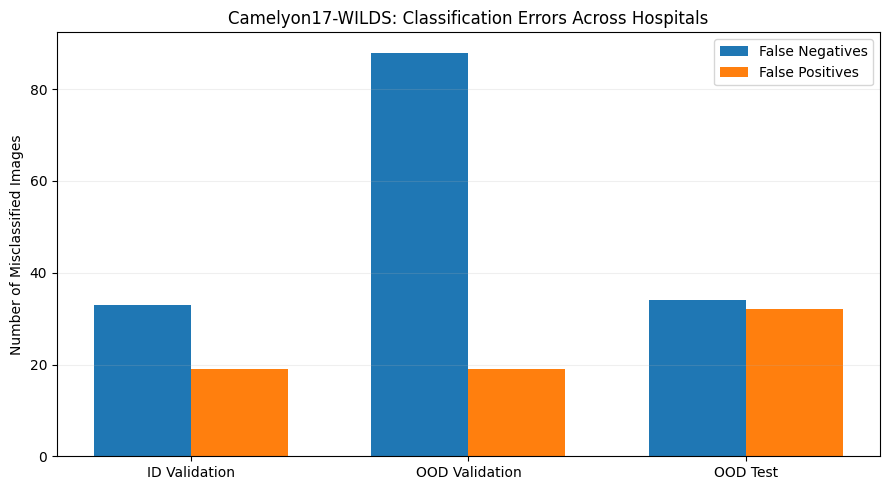

Figure created: True
Saved to: /content/ood_centers_errors.png


In [45]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

environments = ["ID Validation", "OOD Validation", "OOD Test"]
false_negatives = [33, 88, 34]
false_positives = [19, 19, 32]

x = np.arange(len(environments))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    false_negatives,
    width,
    label="False Negatives"
)

ax.bar(
    x + width / 2,
    false_positives,
    width,
    label="False Positives"
)

ax.set_title("Camelyon17-WILDS: Classification Errors Across Hospitals")
ax.set_ylabel("Number of Misclassified Images")
ax.set_xticks(x)
ax.set_xticklabels(environments)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

output = Path("/content/ood_centers_errors.png")
plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("Figure created:", output.exists())
print("Saved to:", output)

In [ ]:
from pathlib import Path
import re

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

# Update the author field
content = re.sub(
    r'^author:.*$',
    'author: "Ndubuisi Chibuogwu"',
    content,
    count=1,
    flags=re.MULTILINE
)

report.write_text(content, encoding="utf-8")

print("Author field updated.")
print("Performance chart:", Path("/content/camelyon17_performance_chart_seed735.png").exists())
print("Error chart:", Path("/content/ood_centers_errors.png").exists())

### Final source corrections before rendering

This cell updates the **Quarto source**, not just the exported Word file. It does not train or evaluate the model.

In [ ]:
from pathlib import Path
import re

report = Path('/content/replication-lab.qmd')
content = report.read_text(encoding='utf-8')

# Final report corrections, safe to run repeatedly.
content = re.sub(r'^author:.*$', 'author: "Ndubuisi Chibuogwu"',
                 content, count=1, flags=re.MULTILINE)
content = re.sub(r'Koh et al\. \(2021\)(?: \[\@koh2021wilds\])?',
                 'Koh et al. [-@koh2021wilds]', content)
content = content.replace('## How closely did your results align with the original study?\n\n', '')
content = content.replace('## What did the replication reveal that you would investigate next?\n\n', '')
content = content.replace('Classification errors at the two unseen hospitals',
                          'Classification errors across all three evaluation environments')
content = content.replace('False-positive and false-negative counts at hospitals 1 and 2.',
                          'False-positive and false-negative counts in ID validation, OOD validation (center 1), and OOD test (center 2).')
report.write_text(content, encoding='utf-8')

print('Author:', next(x for x in content.splitlines() if x.startswith('author:')))
print('Old figure caption remains:', 'at hospitals 1 and 2.' in content)
print('Figure files:', {p: (Path('/content') / p).exists() for p in
      ['camelyon17_performance_chart_seed735.png', 'ood_centers_errors.png']})
print('Bibliography exists:', Path('/content/references.bib').exists())


In [51]:
%cd /content
!quarto render replication-lab.qmd --to docx

/content
pandoc 
  to: docx
  output-file: replication-lab.docx
  default-image-extension: png
  toc: false
  
metadata
  title: 'Replication Laboratory #3 | When the Test Environment Changes'
  subtitle: ANLY 735 – Research Seminar in Predictive AI
  author: Ndubuisi Chibuogwu
  date: today
  bibliography:
    - references.bib
  
Output created: replication-lab.docx



In [48]:
from pathlib import Path

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")

content = content.replace(
    'author: ENTER YOUR FULL NAME',
    'author: "YOUR ACTUAL FULL NAME"'
)

report.write_text(content, encoding="utf-8")

print("Author field corrected.")

Author field corrected.


In [ ]:
from pathlib import Path
import re

report = Path("/content/replication-lab.qmd")
content = report.read_text(encoding="utf-8")
content = re.sub(r'^author:.*$', 'author: "Ndubuisi Chibuogwu"',
                 content, count=1, flags=re.MULTILINE)
report.write_text(content, encoding="utf-8")
print('Author field:', next(x for x in content.splitlines() if x.startswith('author:')))


In [53]:
%pip install python-docx -q

In [54]:
from docx import Document

doc = Document("/content/replication-lab.docx")

print("Embedded images:", len(doc.inline_shapes))
print("Tables:", len(doc.tables))
print("Author:", doc.core_properties.author)

Embedded images: 2
Tables: 2
Author: Ndubuisi Chibuogwu


In [55]:
from google.colab import files

files.download("/content/replication-lab.docx")
files.download("/content/replication-lab.qmd")
files.download("/content/references.bib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>